In [1]:
import sys
src_path = "/home/souvik/codes/foresee-main"
sys.path.append(src_path)

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect

In [2]:
from src_modified.foresee import Foresee, Utility, Model
foresee = Foresee()

energy = "100"
modelname="U1_llzplln_faser"
model = Model(modelname, path="./")

In [3]:
sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast 

In [4]:
model.add_production_2bodydecay(
    pid0 = "111",
    pid1 = "22",
    br = "2*0.99 * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
#     br = "2*0.99 * (coupling)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "221",
    pid1 = "22",
    br = "2*0.25*0.39  * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
#     br = "2*0.39 * (coupling)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50, 
)

In [5]:
masses_brem = [ 
   0.01  ,  0.0126,  0.0158,  0.02  ,  0.0251,  0.0316,  0.0398,
   0.0501,  0.0631,  0.0794,  0.1   ,  0.1122,  0.1259,  0.10013,
   0.1585,  0.1778,  0.1995,  0.2239,  0.2512,  0.2818,  0.3162,
   0.3548,  0.3981,  0.4467,  0.5012,  0.5623,  0.6026,  0.631 ,
   0.6457,  0.6607,  0.6761,  0.6918,  0.7079,  0.7244,  0.7413,
   0.7586,  0.7762,  0.7943,  0.8128,  0.8318,  0.8511,  0.871 ,
   0.8913,  0.912 ,  0.9333,  0.955 ,  0.9772,  1.    ,  1.122 ,
   1.2589,  1.4125,  1.5849,  1.7783,  1.9953,  2.2387,  2.5119,
   2.8184,  3.1623,  3.9811,  5.0119,  6.3096,  7.9433, 10.    
]

model.add_production_direct(
    label = "Brem",
    energy = energy,
    condition = "1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_brem,
)

In [6]:
masses = np.logspace(-3, 1, 100)
masses = np.array(masses)
foresee.set_model(model=model)
# for mass in masses:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=30000, mincount=0,
#                                 do_plot=False, stat_cuts=None, save_file=True)

In [7]:
distance, selection, length, luminosity, channels = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, name = '100', "heavy_LLP2_", "U1_X"
foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, channels=channels, name=name)
foresee.event_gen(masses, energy=energy,
        modes=None, 
        nsample=10, U=1e-3,
        preselectioncuts="th<np.sqrt(200)/1500",
        coup_ref=1, 
        extend_to_low_pt_scales={},
        )

In [8]:
%%time
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH = -1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
                                                     mN1=1000, mN2=1000, mN3=1000)
    list_nevents.append(nevents)  
#save results
np.save("model/results_RHN3/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 5min 28s, sys: 628 ms, total: 5min 29s
Wall time: 5min 29s


/home/souvik/anaconda3/lib/python3.11/site-packages/numpy/lib/npyio.py:521: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.asanyarray(arr)


In [9]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

In [10]:
distance, selection, length, luminosity, channels = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, name = '100', "default_LLP2_", "U1_X"
foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, channels=channels, name=name)
foresee.event_gen(masses, energy=energy,
        modes=None, 
        nsample=10, U=1e-3,
        preselectioncuts="th<np.sqrt(200)/1500",
        coup_ref=1, 
        extend_to_low_pt_scales={},
        )

In [11]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-2, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
                                                     mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 5min 50s, sys: 1.15 s, total: 5min 51s
Wall time: 5min 52s


In [12]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_10194/672541521.py:22: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
/tmp/ipykernel_10194/672541521.py:37: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")


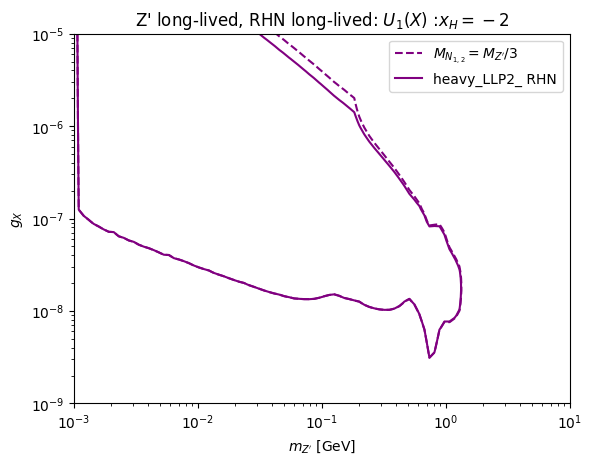

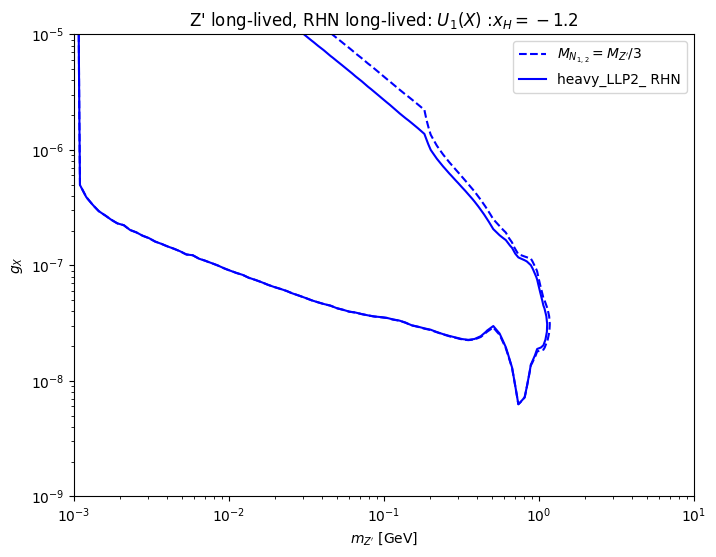

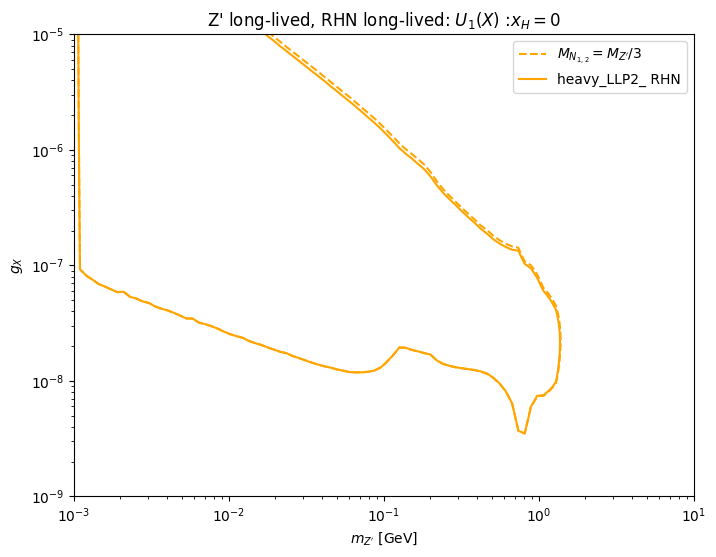

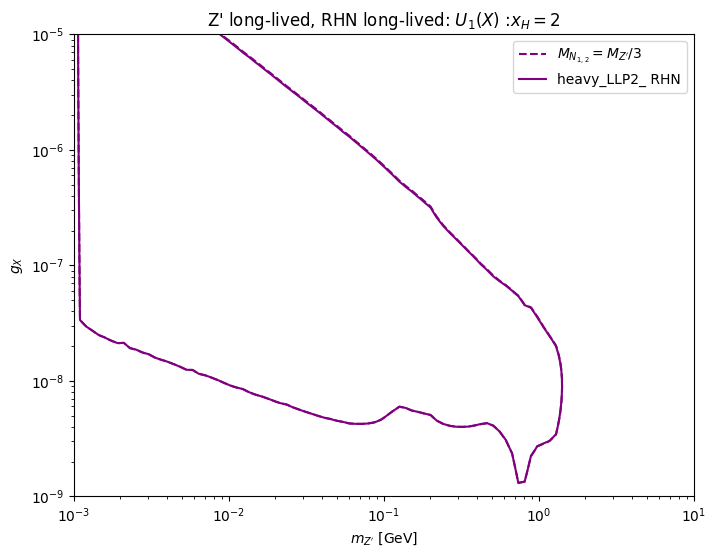

In [13]:
setupsH = [
         ["100TeV_heavy_LLP2_2n",    r"$x_H = -2$"  , "purple", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP2_12n",    r"$x_H = -1.2$"  , "blue", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP2_0",    r"$x_H = 0$"  , "orange", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP2_2p",    r"$x_H = 2$"  , "purple", "dashed", 0., 3]#*150/3000]]
]
setups = [
         ["100TeV_default_LLP2_2n",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_12n",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_0",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000], 
         ["100TeV_default_LLP2_2p",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]


for setup, setuph in zip(setups, setupsH):
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setuph
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
    ax.plot([0],[0],label=r"$M_{N_{1,2}}=M_{Z'}/3$", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")
    ax.plot([0],[0],label="heavy_LLP2_ RHN", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    ax.legend()
    ax.set_title(r"Z' long-lived, RHN long-lived: $U_1(X)$ :"+label)
    plt.savefig(model.modelpath+"model/results_RHN3/plots/"+filename+".png")
    plt.show()

In [14]:
distance, selection, length, luminosity, channels = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, name = '100', "alternative_LLP2_", "U1_X_phi4"
foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, channels=channels, name=name)
foresee.event_gen(masses, energy=energy,
        modes=None, 
        nsample=10, U=1e-3,
        preselectioncuts="th<np.sqrt(200)/1500",
        coup_ref=1, 
        extend_to_low_pt_scales={},
        )

In [15]:
%%time
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = -1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
                                                     mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 6min 28s, sys: 1.73 s, total: 6min 30s
Wall time: 6min 30s


In [16]:
# %%time
# # get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_10194/4162451782.py:22: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
/tmp/ipykernel_10194/4162451782.py:37: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")


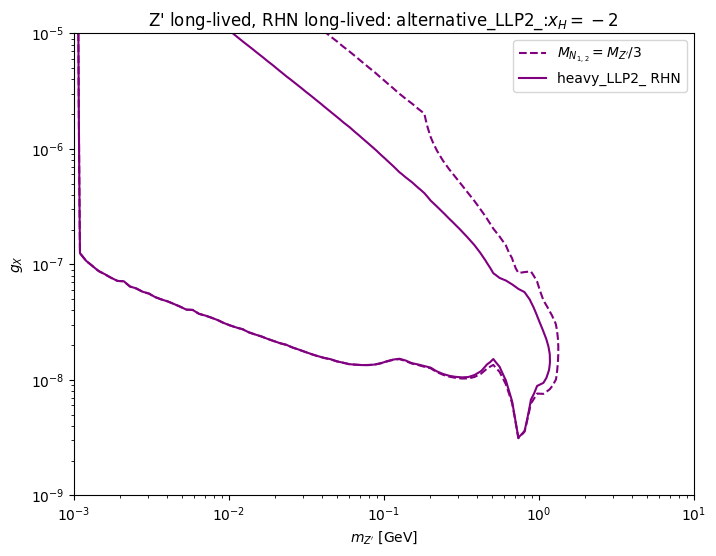

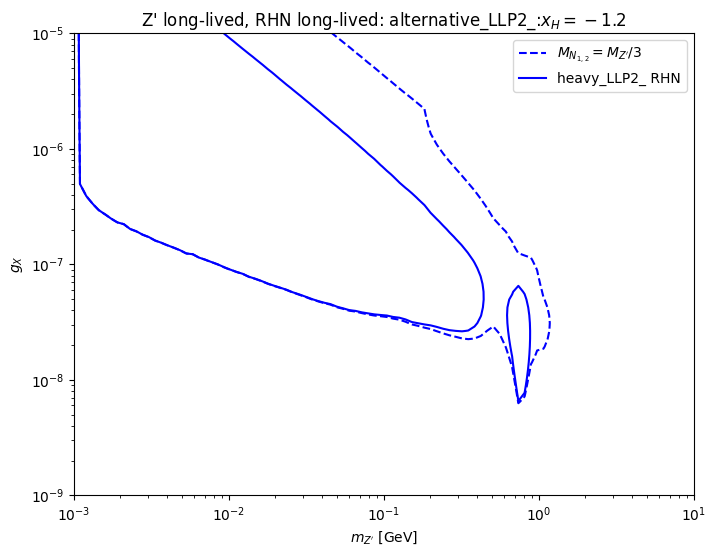

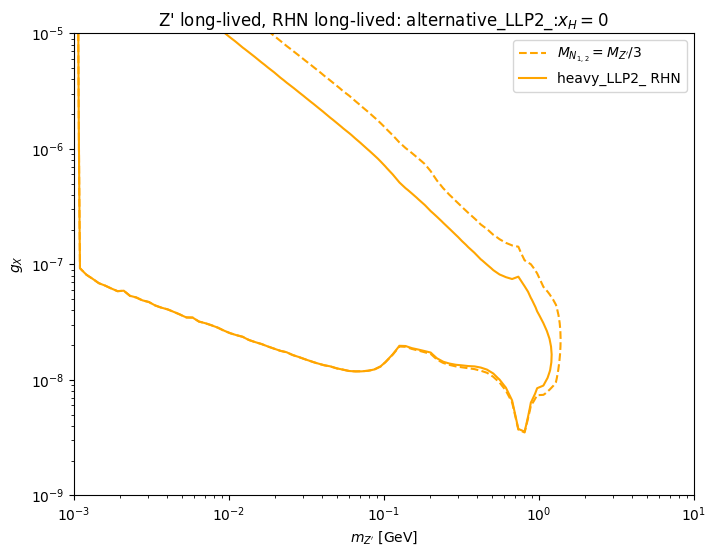

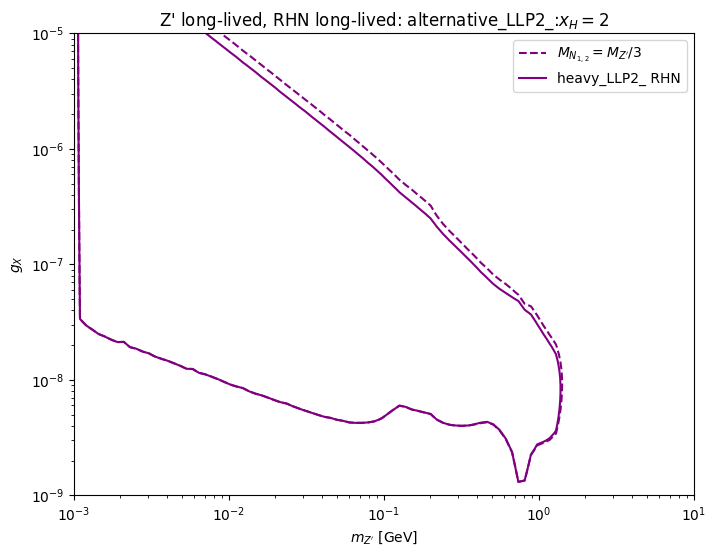

In [17]:
setupsH = [
         ["100TeV_heavy_LLP2_2n",    r"$x_H = -2$"  , "purple", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP2_12n",    r"$x_H = -1.2$"  , "blue", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP2_0",    r"$x_H = 0$"  , "orange", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP2_2p",    r"$x_H = 2$"  , "purple", "dashed", 0., 3]#*150/3000]]
]
setups = [
         ["100TeV_alternative_LLP2_2n",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_12n",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_0",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000], 
         ["100TeV_alternative_LLP2_2p",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]


for setup, setuph in zip(setups, setupsH):
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setuph
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
    ax.plot([0],[0],label=r"$M_{N_{1,2}}=M_{Z'}/3$", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")
    ax.plot([0],[0],label="heavy_LLP2_ RHN", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    ax.legend()
    ax.set_title(r"Z' long-lived, RHN long-lived: alternative_LLP2_:"+label)
    # plt.savefig(model.modelpath+"model/results_RHN3/plots/"+filename+".png")

In [18]:
distance, selection, length, luminosity, channels = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, name = '100', "heavy_LLP1_", "U1_X"
foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, channels=channels, name=name)
foresee.event_gen(masses, energy=energy,
        modes=None, 
        nsample=10, U=1e-3,
        preselectioncuts="th<np.sqrt(12.5)/1500",
        coup_ref=1, 
        extend_to_low_pt_scales={},
        )

In [19]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
                                                     mN1=1000, mN2=1000, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 5min 52s, sys: 1.54 s, total: 5min 53s
Wall time: 5min 53s


In [20]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1000, mN2=1000, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

In [21]:
distance, selection, length, luminosity, channels = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, name = '100', "default_LLP1_", "U1_X"
foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, channels=channels, name=name)
foresee.event_gen(masses, energy=energy,
        modes=None, 
        nsample=10, U=1e-3,
        preselectioncuts="th<np.sqrt(12.5)/1500",
        coup_ref=1, 
        extend_to_low_pt_scales={},
        )

In [22]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
                                                     mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 6min 14s, sys: 1.55 s, total: 6min 16s
Wall time: 6min 16s


In [23]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_10194/3405991713.py:22: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
/tmp/ipykernel_10194/3405991713.py:37: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")


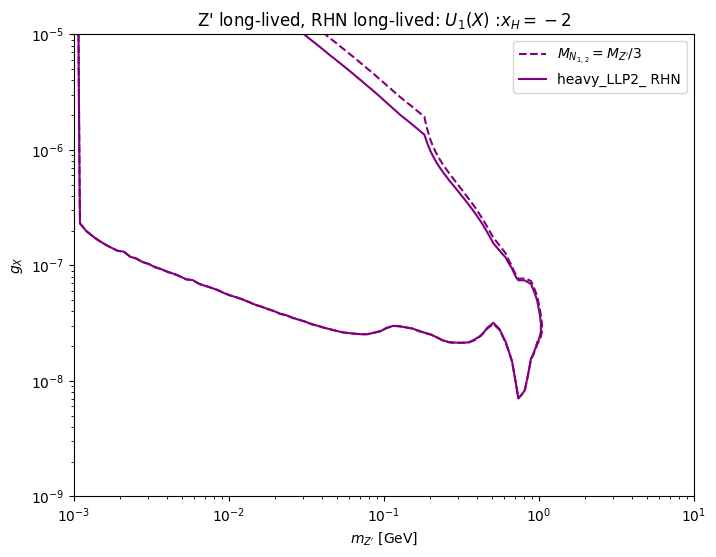

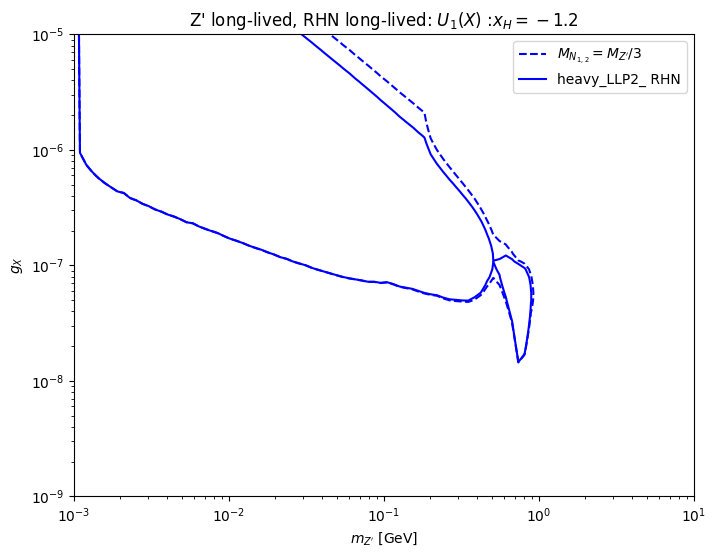

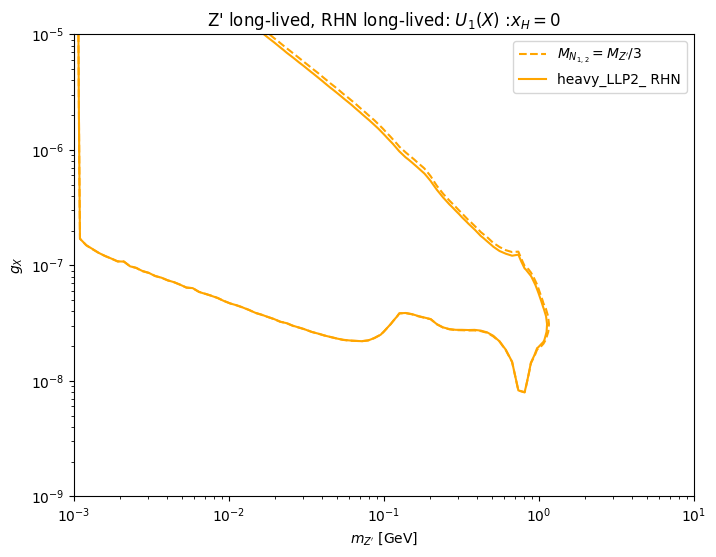

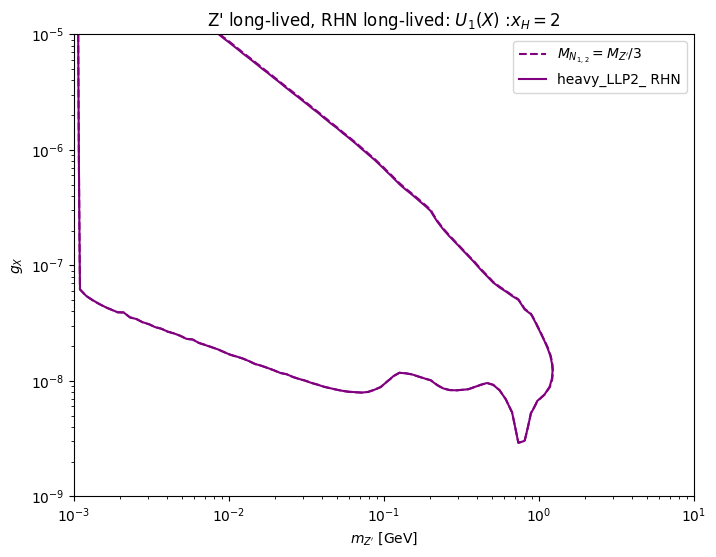

In [24]:
setupsH = [
         ["100TeV_heavy_LLP1_2n",    r"$x_H = -2$"  , "purple", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP1_12n",    r"$x_H = -1.2$"  , "blue", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP1_0",    r"$x_H = 0$"  , "orange", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP1_2p",    r"$x_H = 2$"  , "purple", "dashed", 0., 3]#*150/3000]]
]
setups = [
         ["100TeV_default_LLP1_2n",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_12n",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_0",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000], 
         ["100TeV_default_LLP1_2p",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]


for setup, setuph in zip(setups, setupsH):
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setuph
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
    ax.plot([0],[0],label=r"$M_{N_{1,2}}=M_{Z'}/3$", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")
    ax.plot([0],[0],label="heavy_LLP2_ RHN", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    ax.legend()
    ax.set_title(r"Z' long-lived, RHN long-lived: $U_1(X)$ :"+label)
    plt.savefig(model.modelpath+"model/results_RHN3/plots/"+filename+".png")
    plt.show()

In [25]:
distance, selection, length, luminosity, channels = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000, ["e_e", "mu_mu", "tau_tau", "hadrons"]
energy, setup, name = '100', "alternative_LLP1_", "U1_X_phi4"
foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, channels=channels, name=name)
foresee.event_gen(masses, energy=energy,
        modes=None, 
        nsample=10, U=1e-3,
        preselectioncuts="th<np.sqrt(12.5)/1500",
        coup_ref=1, 
        extend_to_low_pt_scales={},
        )

In [26]:
%%time
# get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
                                                     mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])


CPU times: user 6min 39s, sys: 1.48 s, total: 6min 40s
Wall time: 6min 40s


In [27]:
# %%time
# # get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     couplings, _, nevents, _, _  = foresee.get_events(nsample=1, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-9,-5,60), preselectioncuts="th<1/630",
#                                                      mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
# np.save("model/results_RHN3/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_10194/2789340048.py:22: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
/tmp/ipykernel_10194/2789340048.py:37: UserWarning: The following kwargs were not used by contour: 'label'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")


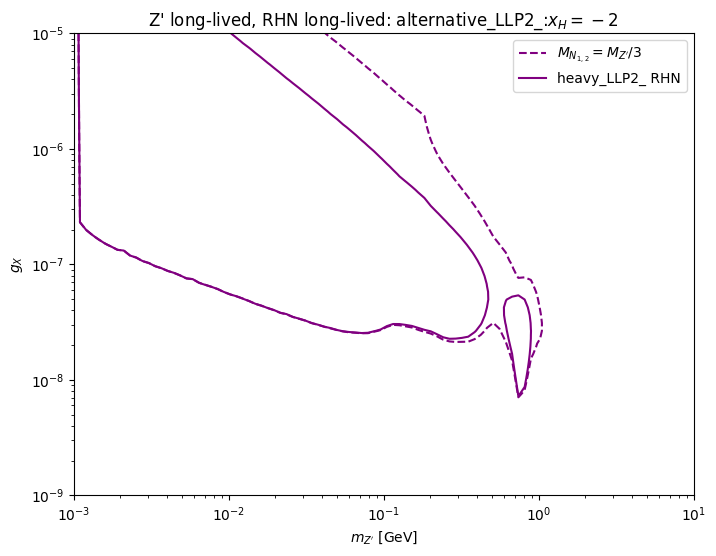

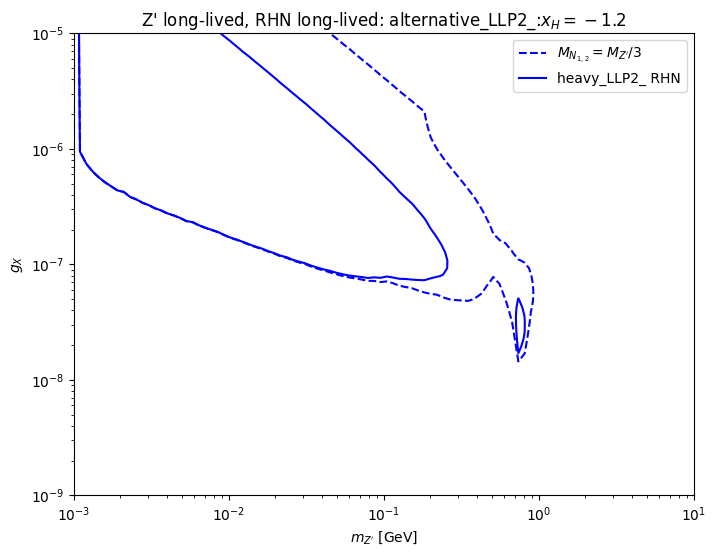

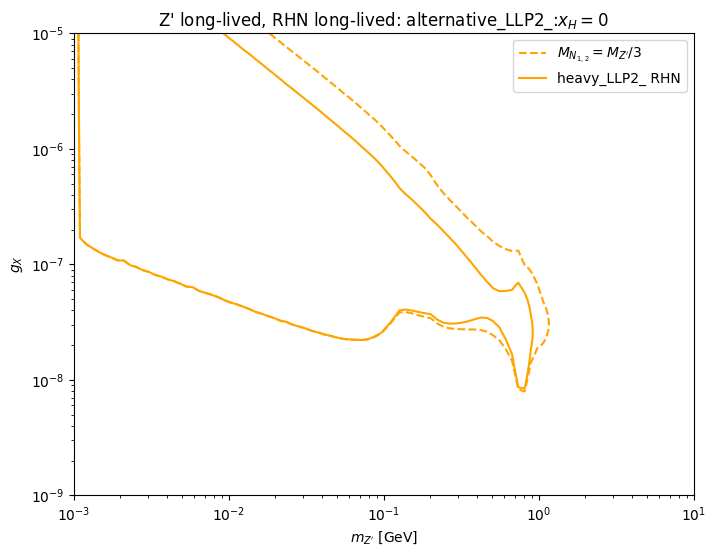

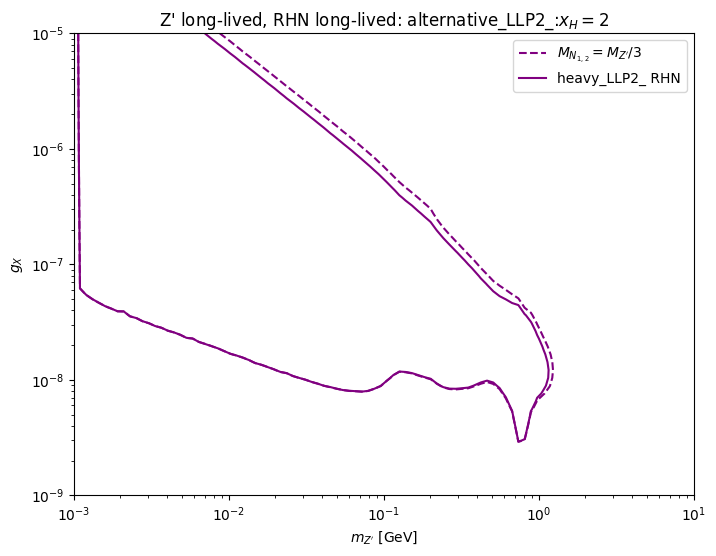

In [28]:
setupsH = [
         ["100TeV_heavy_LLP1_2n",    r"$x_H = -2$"  , "purple", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP1_12n",    r"$x_H = -1.2$"  , "blue", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP1_0",    r"$x_H = 0$"  , "orange", "dashed", 0., 3],#*150/3000],
         ["100TeV_heavy_LLP1_2p",    r"$x_H = 2$"  , "purple", "dashed", 0., 3]#*150/3000]]
]
setups = [
         ["100TeV_alternative_LLP1_2n",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_12n",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_0",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000], 
         ["100TeV_alternative_LLP1_2p",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]


for setup, setuph in zip(setups, setupsH):
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setuph
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label=r"$M_{N_{1,2}}=M_{Z'}/3$")
    ax.plot([0],[0],label=r"$M_{N_{1,2}}=M_{Z'}/3$", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3/"+filename+".npy", allow_pickle=True, encoding='latin1')
    # m, c, n = masses,couplings,nsignals #changed
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, label="heavy_LLP2_ RHN")
    ax.plot([0],[0],label="heavy_LLP2_ RHN", color=color, linestyle=ls)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-9, 1e-5)
    ax.legend()
    ax.set_title(r"Z' long-lived, RHN long-lived: alternative_LLP2_:"+label)
    # plt.savefig(model.modelpath+"model/results_RHN3/plots/"+filename+".png")